In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/fire_incidents_cleaned.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (36564, 43)


C:\Users\BSE\AppData\Local\Temp\ipykernel_22456\3789454756.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/fire_incidents_cleaned.csv")


,_id,incident_number,initial_cad_event_type,final_incident_type,exposures,incident_station_area,incident_ward,intersection,latitude,longitude,...,possible_cause,smoke_alarm_at_fire_origin,smoke_alarm_at_fire_origin_alarm_failure,smoke_alarm_at_fire_origin_alarm_type,smoke_alarm_impact_on_persons_evacuating_impact_on_evacuation,fire_alarm_system_presence,fire_alarm_system_operation,fire_alarm_system_impact_on_evacuation,sprinkler_system_presence,sprinkler_system_operation
0,1,F18020956,Vehicle Fire,01 - Fire,NaN,441,1.0,Dixon Rd / 427 N Dixon Ramp,43.686558,-79.599419,...,99 - Undetermined,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F18020969,Fire - Grass/Rubbish,01 - Fire,NaN,116,18.0,Sheppard Ave E / Clairtrell Rd,43.766135,-79.390039,...,03 - Suspected Vandalism,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,F18021182,Fire - Highrise Residential,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN,221,21.0,Danforth Rd / Savarin St,43.743230,-79.245061,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,F18021192,Fire - Commercial/Industrial,01 - Fire,NaN,133,5.0,Keele St / Lawrence Ave W,43.708659,-79.478062,...,99 - Undetermined,9 - Floor/suite of fire origin: Smoke alarm pr...,98 - Not applicable: Alarm operated OR presenc...,9 - Type undetermined,"8 - Not applicable: No alarm, no persons present",9 - Undetermined,8 - Not applicable (no system),9 - Undetermined,9 - Undetermined,8 - Not applicable - no sprinkler system present
4,5,F18021271,Fire - Residential,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN,132,8.0,Replin Rd / Tapestry Lane,43.718118,-79.443184,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
display(
    df[
        ["final_incident_type", "estimated_dollar_loss"]
    ].head(10)
)

,final_incident_type,estimated_dollar_loss
0,01 - Fire,15000.0
1,01 - Fire,50.0
2,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN
3,01 - Fire,0.0
4,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN
5,01 - Fire,1500.0
6,01 - Fire,2000.0
7,01 - Fire,100000.0
8,01 - Fire,5000.0
9,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN


counting incidents by type

In [4]:
df["final_incident_type"].value_counts()

final_incident_type
01 - Fire                                                                                  26029
03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)    10384
02 - Explosion (including during Fire, excluding Codes 3 & 11-13)                            151
Name: count, dtype: int64

checking missing dollar values by incident type

In [5]:
loss_summary = df.groupby("final_incident_type").agg(
    total_incidents=("incident_number", "count"),
    valid_loss_records=("estimated_dollar_loss", "count"),
    missing_loss_records=("estimated_dollar_loss", lambda x: x.isna().sum())
)

loss_summary["missing_percentage"] = (
    loss_summary["missing_loss_records"]
    / loss_summary["total_incidents"] * 100
).round(2)

display(loss_summary)

,total_incidents,valid_loss_records,missing_loss_records,missing_percentage
final_incident_type,,,,
01 - Fire,26029,25804,225,0.86
"02 - Explosion (including during Fire, excluding Codes 3 & 11-13)",151,146,5,3.31
"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)",10384,699,9685,93.27


creating dollar loss analysis dataset

In [6]:
# Keep only incidents with recorded dollar-loss values
df_loss = df.dropna(
    subset=["estimated_dollar_loss"]
).copy()

print("Original incidents:", len(df))
print("Incidents with recorded dollar loss:", len(df_loss))
print("Excluded missing loss records:", len(df) - len(df_loss))

Original incidents: 36564
Incidents with recorded dollar loss: 26649
Excluded missing loss records: 9915


calculate dollar loss statistics

In [7]:
loss_by_type = df_loss.groupby("final_incident_type").agg(
    incident_count=("estimated_dollar_loss", "count"),
    total_dollar_loss=("estimated_dollar_loss", "sum"),
    average_dollar_loss=("estimated_dollar_loss", "mean"),
    median_dollar_loss=("estimated_dollar_loss", "median")
)

# Round financial values to 2 decimal places
loss_by_type = loss_by_type.round(2)

# Sort from highest to lowest total dollar loss
loss_by_type = loss_by_type.sort_values(
    by="total_dollar_loss",
    ascending=False
)

display(loss_by_type)

,incident_count,total_dollar_loss,average_dollar_loss,median_dollar_loss
final_incident_type,,,,
01 - Fire,25804,990779695.0,38396.36,4000.0
"02 - Explosion (including during Fire, excluding Codes 3 & 11-13)",146,7655287.0,52433.47,2000.0
"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)",699,140.0,0.20,0.0


average vs median dollar loss

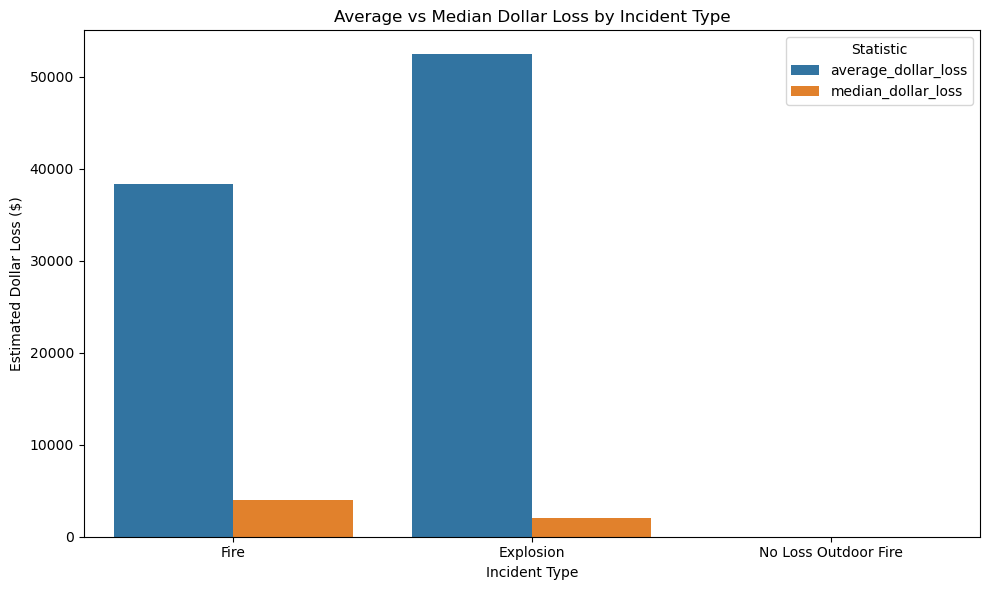

In [8]:
# Prepare data for visualization
plot_data = loss_by_type.reset_index().copy()

# Shorten category names for the chart
plot_data["incident_type"] = [
    "Fire",
    "Explosion",
    "No Loss Outdoor Fire"
]

# Reshape the data
plot_data = plot_data.melt(
    id_vars="incident_type",
    value_vars=["average_dollar_loss", "median_dollar_loss"],
    var_name="Statistic",
    value_name="Dollar Loss"
)

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="incident_type",
    y="Dollar Loss",
    hue="Statistic"
)

plt.title("Average vs Median Dollar Loss by Incident Type")
plt.xlabel("Incident Type")
plt.ylabel("Estimated Dollar Loss ($)")
plt.legend(title="Statistic")
plt.tight_layout()
plt.show()

investigate whether the condition or status of a building is associated with higher financial losses.

 Check building status categories

In [9]:
print(df_loss["building_status"].value_counts(dropna=False))

building_status
01 - Normal (no change)               15689
NaN                                    8576
08 - Not Applicable                    1070
02 - Under Renovation                   747
03 - Under Construction                 244
09 - Undetermined                       161
05 - Abandoned, vacant (long term)      142
04 - Under Demolition                    20
Name: count, dtype: int64


calculate dollar loss by building

In [10]:
# Calculate financial losses by building status
building_loss = df_loss.groupby(
    "building_status",
    dropna=False
).agg(
    incident_count=("estimated_dollar_loss", "count"),
    total_loss=("estimated_dollar_loss", "sum"),
    average_loss=("estimated_dollar_loss", "mean"),
    median_loss=("estimated_dollar_loss", "median")
)

# Round the results
building_loss = building_loss.round(2)

# Sort by highest total loss
building_loss = building_loss.sort_values(
    by="total_loss",
    ascending=False
)

display(building_loss)

,incident_count,total_loss,average_loss,median_loss
building_status,,,,
01 - Normal (no change),15689,668235168.0,42592.59,3000.0
NaN,8576,155717288.0,18157.33,4000.0
02 - Under Renovation,747,52740576.0,70603.18,10000.0
03 - Under Construction,244,46235727.0,189490.68,5000.0
08 - Not Applicable,1070,39601227.0,37010.49,2000.0
09 - Undetermined,161,20851379.0,129511.67,20000.0
"05 - Abandoned, vacant (long term)",142,14801053.0,104232.77,10000.0
04 - Under Demolition,20,252704.0,12635.20,100.5


dollar loss by building status

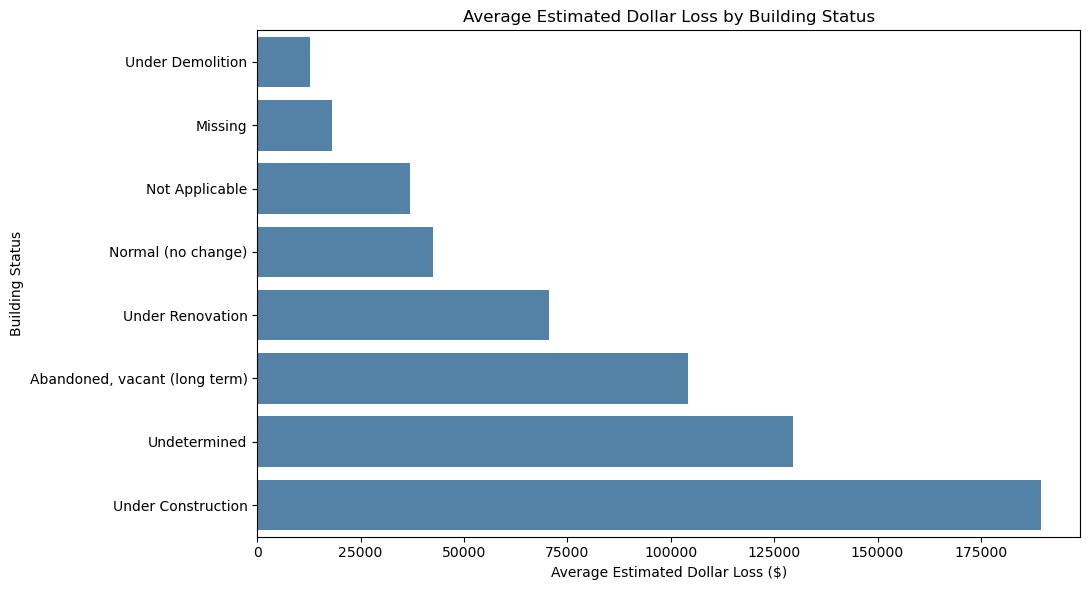

In [11]:
# Prepare data for visualization
building_plot = building_loss.reset_index().copy()

# Replace missing category labels for display only
building_plot["building_status"] = (
    building_plot["building_status"]
    .fillna("Missing")
    .str.replace(r"^\d+\s*-\s*", "", regex=True)
)

# Sort by average dollar loss
building_plot = building_plot.sort_values(
    "average_loss",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=building_plot,
    x="average_loss",
    y="building_status",
    color="steelblue"
)

plt.title("Average Estimated Dollar Loss by Building Status")
plt.xlabel("Average Estimated Dollar Loss ($)")
plt.ylabel("Building Status")

plt.tight_layout()
plt.show()

explore extent of fire

In [12]:
# Check the different extent-of-fire categories
print(
    df_loss["extent_of_fire"].value_counts(
        dropna=False
    )
)

extent_of_fire
NaN                                                                                 8580
1 - Confined to object of origin                                                    8371
2 - Confined to part of room/area of origin                                         6385
3 - Spread to entire room of origin                                                  787
4 - Spread beyond room of origin, same floor                                         744
9 - Confined to roof/exterior structure                                              622
7 - Spread to other floors, confined to building                                     425
11 - Spread beyond building of origin, resulted in exposure fire(s)                  198
8 - Entire Structure                                                                 163
99 - Undetermined                                                                    160
10 - Spread beyond building of origin                                                 94
5 - Mu

calculate dollar loss by extend of fire

In [13]:

extent_loss = df_loss.groupby(
    "extent_of_fire",
    dropna=False
).agg(
    incident_count=("estimated_dollar_loss", "count"),
    total_loss=("estimated_dollar_loss", "sum"),
    average_loss=("estimated_dollar_loss", "mean"),
    median_loss=("estimated_dollar_loss", "median")
)

# Round financial values
extent_loss = extent_loss.round(2)

# Sort by highest average dollar loss
extent_loss = extent_loss.sort_values(
    by="average_loss",
    ascending=False
)

display(extent_loss)

,incident_count,total_loss,average_loss,median_loss
extent_of_fire,,,,
8 - Entire Structure,163,123794700.0,759476.69,100000.0
6 - Multi unit bldg: spread to separate suite(s),60,22504000.0,375066.67,100000.0
"7 - Spread to other floors, confined to building",425,154609500.0,363787.06,150000.0
"11 - Spread beyond building of origin, resulted in exposure fire(s)",198,65933749.0,332998.73,100000.0
5 - Multi unit bldg: spread beyond suite of origin but not to separated suite(s),60,12978119.0,216301.98,100000.0
10 - Spread beyond building of origin,94,16831730.0,179060.96,50000.0
"4 - Spread beyond room of origin, same floor",744,115876349.0,155747.78,80000.0
3 - Spread to entire room of origin,787,64611691.0,82098.72,50000.0
9 - Confined to roof/exterior structure,622,30315818.0,48739.26,10000.0


average dollar loss by extent of fire

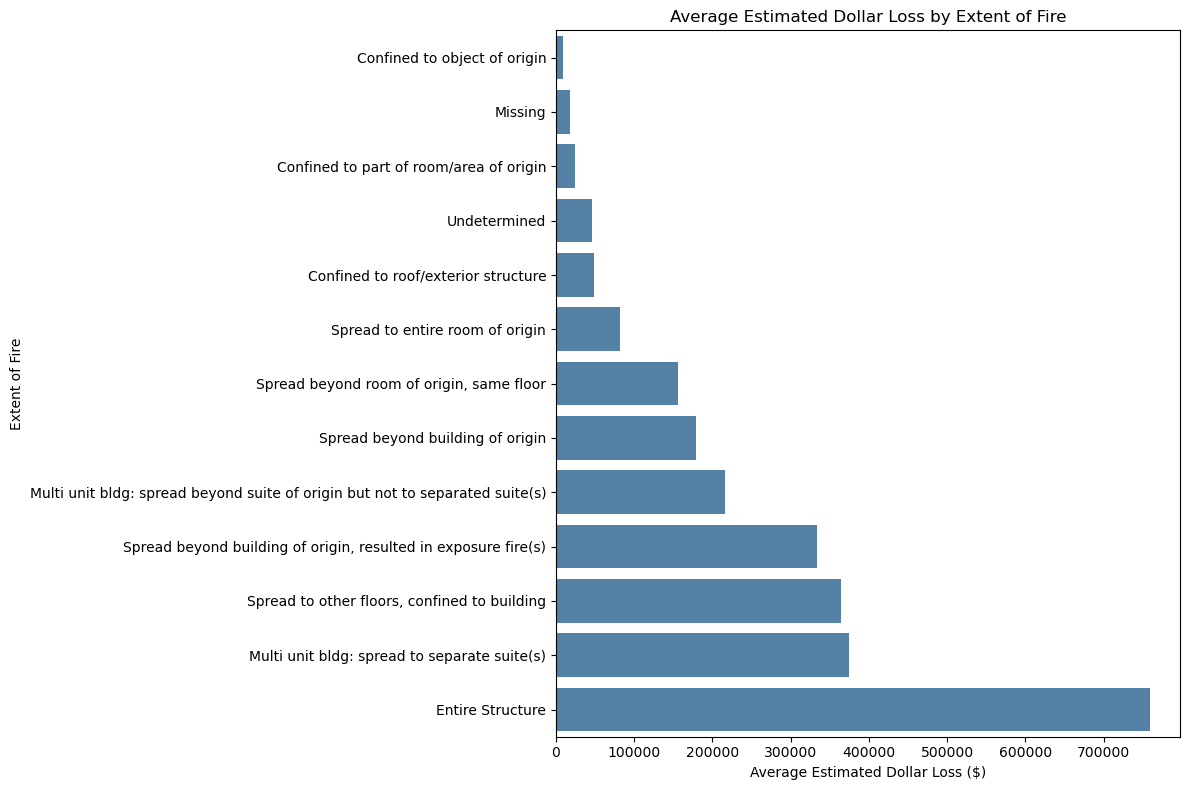

In [14]:
# Prepare data for visualization
extent_plot = extent_loss.reset_index().copy()

# Replace missing labels for visualization
extent_plot["extent_of_fire"] = (
    extent_plot["extent_of_fire"]
    .fillna("Missing")
    .str.replace(r"^\d+\s*-\s*", "", regex=True)
)

# Sort by average loss
extent_plot = extent_plot.sort_values(
    "average_loss",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

sns.barplot(
    data=extent_plot,
    x="average_loss",
    y="extent_of_fire",
    color="steelblue"
)

plt.title("Average Estimated Dollar Loss by Extent of Fire")
plt.xlabel("Average Estimated Dollar Loss ($)")
plt.ylabel("Extent of Fire")

plt.tight_layout()
plt.show()

Analyze dollar loss by location

1 - Dollar loss by ward

In [15]:
ward_loss = df_loss.groupby(
    "incident_ward",
    dropna=False
).agg(
    incident_count=("estimated_dollar_loss", "count"),
    total_loss=("estimated_dollar_loss", "sum"),
    average_loss=("estimated_dollar_loss", "mean"),
    median_loss=("estimated_dollar_loss", "median")
)

ward_loss = ward_loss.round(2)

ward_loss = ward_loss.sort_values(
    by="total_loss",
    ascending=False
)

display(ward_loss.head(10))

,incident_count,total_loss,average_loss,median_loss
incident_ward,,,,
5.0,1110,90225044.0,81283.82,5000.0
7.0,1432,58239762.0,40670.22,5000.0
20.0,1208,44535969.0,36867.52,2500.0
2.0,851,43840037.0,51515.91,5000.0
25.0,742,41632693.0,56108.75,10000.0
15.0,648,41497999.0,64040.12,5000.0
11.0,1057,41069679.0,38854.95,1000.0
6.0,998,35895323.0,35967.26,5000.0
1.0,1091,35701559.0,32723.70,6000.0


total dollar loss by ward

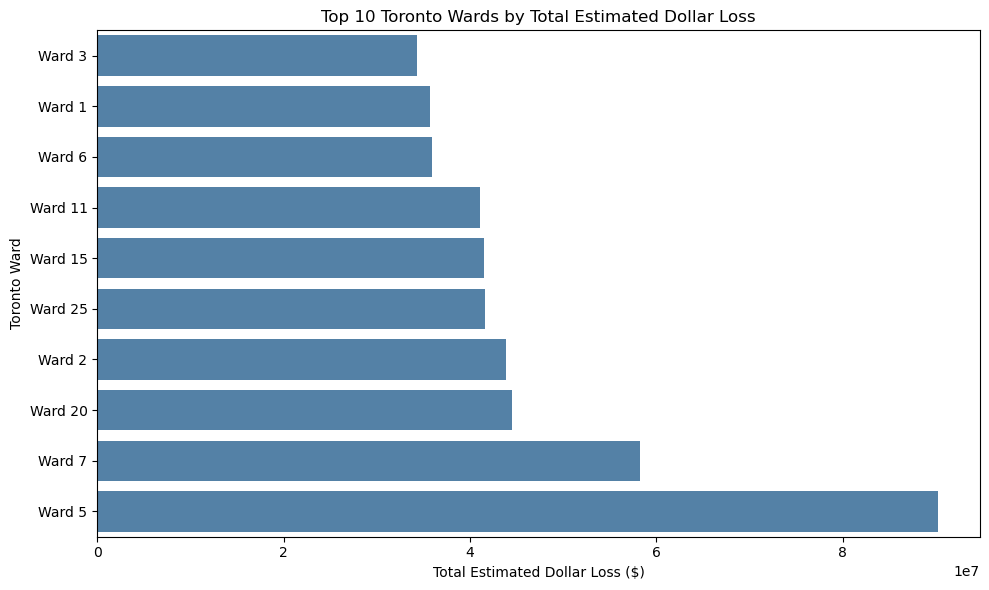

In [16]:
# Select the top 10 wards
top_10_wards = ward_loss.head(10).reset_index().copy()

# Convert ward numbers into labels
top_10_wards["ward_label"] = (
    "Ward " + top_10_wards["incident_ward"].astype(int).astype(str)
)

# Sort for horizontal visualization
top_10_wards = top_10_wards.sort_values(
    "total_loss",
    ascending=True
)

# Create chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_wards,
    x="total_loss",
    y="ward_label",
    color="steelblue"
)

plt.title("Top 10 Toronto Wards by Total Estimated Dollar Loss")
plt.xlabel("Total Estimated Dollar Loss ($)")
plt.ylabel("Toronto Ward")

plt.tight_layout()
plt.show()